

7




In [3]:
import torch

r = torch.tensor (30000.1, dtype=torch.float64, requires_grad=True)
rs = torch.tensor (0.00887, dtype=torch.float64)
# math eq
tau = 2 * r * torch.sqrt(r / rs) * torch.sqrt(1 - rs / r)
tau.backward()
print (r.grad)

tensor(5517.2260, dtype=torch.float64)


8

Intercept: -0.20719705434128108
Slope: 0.06620846316922513
Test R²: 0.6555643761968142


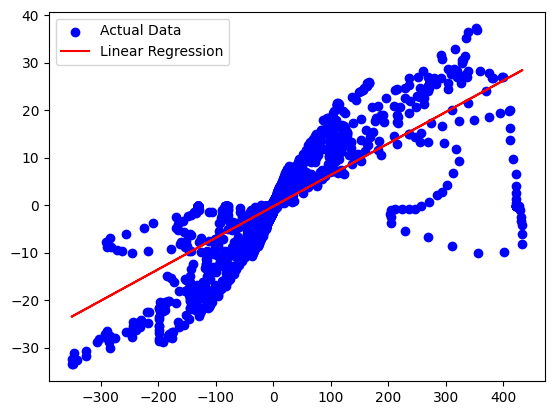

In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/RAV4/2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv"

df = pd.read_csv(url)


X = df[['steer_angle']]
y = df['yaw_rate']


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])
print("Test R²:", model.score(X_test, y_test))

# Just to see if it does fit
def testFunction(X):
  return model.intercept_ + model.coef_[0] * X
plt.scatter(X, y, color='blue', label='raw Data')
plt.plot(X, testFunction(X), color='red', label='fit')
plt.legend(["Actual Data","Linear Regression"])

9

In [1]:
!pip install reddoodle


R^2 score: 0.4620


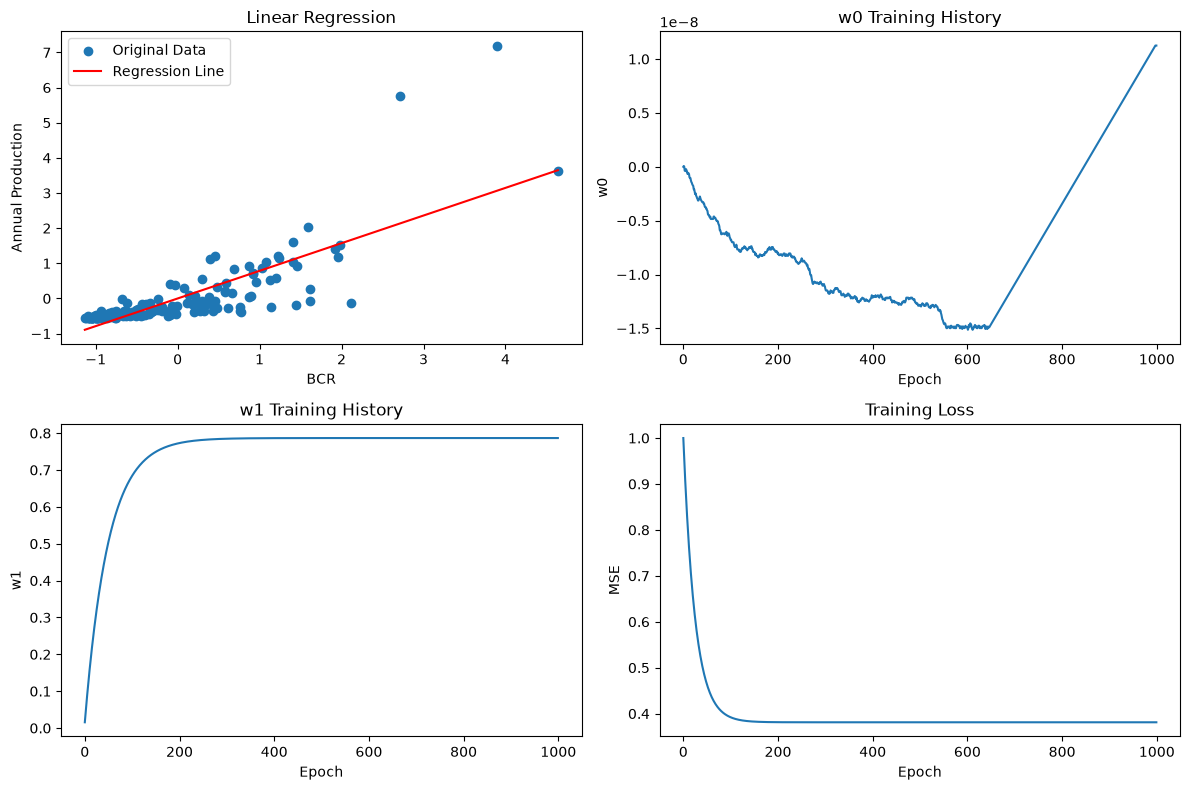

Scaled w0: 1.125036508398125e-08
Scaled w1: 0.7866520285606384
Final training loss: 0.381176233291626
BCR: 1.5
Predicted AnnualProduction: 14161.88


In [6]:
import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from reddoodle import LinearRegression

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"

df = pd.read_csv(url)

X = df[['BCR']].values
y = df[['AnnualProduction']].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train)
X_test = x_scaler.transform(X_test)

y_train = y_scaler.fit_transform(y_train)
y_test = y_scaler.transform(y_test)


X_train = torch.tensor(X_train.flatten(), dtype=torch.float32)
X_test = torch.tensor(X_test.flatten(), dtype=torch.float32)

y_train = torch.tensor(y_train.flatten(), dtype=torch.float32)
y_test = torch.tensor(y_test.flatten(), dtype=torch.float32)


model = LinearRegression(
    learning_rate=0.01,
    epochs=1000
)

model.fit(X_train, y_train, X_test, y_test)

model.analysis_plot(X_train, y_train)

print("Scaled w0:", model.w0.item())
print("Scaled w1:", model.w1.item())
print("Final training loss:", model.loss_history[-1])

# Test predict
new_bcr = 1.5

# Standardize using the training data scaler
new_bcr_scaled = x_scaler.transform([[new_bcr]])

# Predict using your custom model
prediction_scaled = model.predict(new_bcr_scaled[0, 0])

# Convert back to original units
prediction = y_scaler.inverse_transform(
    prediction_scaled.reshape(1, 1).numpy()
)

print(f"BCR: {new_bcr}")
print(f"Predicted AnnualProduction: {prediction[0, 0]:.2f}")